# Graph-based product recommendation
**Exploratory baseline (NetworkX)** — educational first version. No transaction-level holdout is implemented here; do not use its recommendations as an unbiased performance estimate.

**Dataset:** the UCI *Online Retail* file must be downloaded to `data/Online_Retail.xlsx`; see the root README.

**Next step:** the evaluated recommender (invoice holdout, Jaccard/Lift, Leiden refinement and Neo4j) is in `02_networkx_leiden_neo4j.ipynb`.


# Exploración inicial — recomendador de productos con grafos
Primera versión: los nodos son descripciones de producto y la recomendación se basa en la co-compra dentro de la misma comunidad.

In [1]:
# Run from the repository root so `data/` and `artifacts/` resolve correctly,
# whether Jupyter was opened from the root or from `notebooks/`.
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

## *1. Carga de Librerías y Datos*

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
# Grafos
import networkx as nx
from itertools import combinations
from collections import Counter
from community import community_louvain

In [3]:
# Cargar el archivo Excel en un DataFrame
df = pd.read_excel('data/Online_Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## *2. Análisis Exploratorio (EDA)*

In [4]:
# Vista rápida: dimensiones, tipos, nulos y duplicados en una sola tabla
resumen = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos_%': (df.isnull().mean() * 100).round(1),
    'unicos': df.nunique()
})
print(f'{df.shape[0]:,} filas × {df.shape[1]} columnas | duplicados: {df.duplicated().sum():,}')
print(f'Rango temporal: {df.InvoiceDate.min():%Y-%m-%d} → {df.InvoiceDate.max():%Y-%m-%d}')
resumen

541,909 filas × 8 columnas | duplicados: 5,268
Rango temporal: 2010-12-01 → 2011-12-09


,tipo,nulos_%,unicos
InvoiceNo,object,0.0,25900
StockCode,object,0.0,4070
Description,object,0.3,4223
Quantity,int64,0.0,722
InvoiceDate,datetime64[us],0.0,23260
UnitPrice,float64,0.0,1630
CustomerID,float64,24.9,4372
Country,str,0.0,38


### *2.1 Calidad de los datos*

Visualizamos los casos que nos generan más problemas para nuestro grafo: nulos, cancelaciones, cantidades negativas y precios a cero.

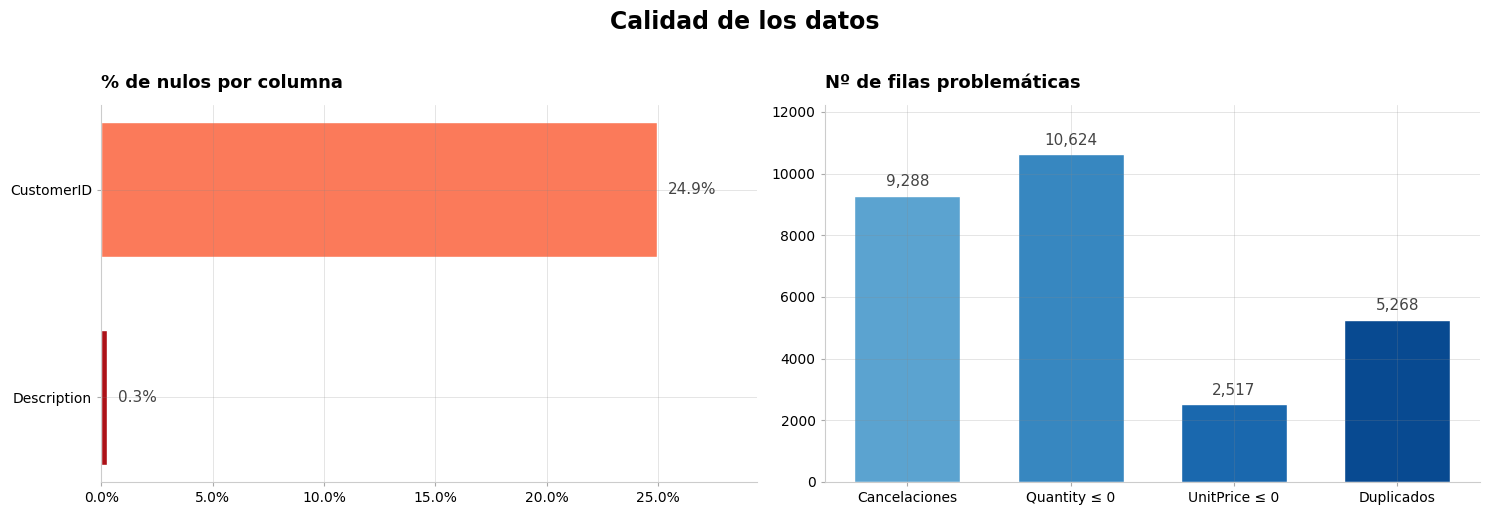

In [5]:
df['is_cancel'] = df['InvoiceNo'].astype(str).str.startswith('C')

# --- Estilo base ---
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8,
})

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Calidad de los datos', fontsize=17, fontweight='bold', y=1.02)

# ---------- Panel 1: Nulos por columna ----------
nulos = (df.isnull().mean() * 100).sort_values(ascending=False)
nulos = nulos[nulos > 0]

grad = plt.cm.Reds(np.linspace(0.45, 0.85, len(nulos)))
bars = ax[0].barh(nulos.index, nulos.values, color=grad, edgecolor='white', height=0.65)
ax[0].invert_yaxis()
ax[0].set_title('% de nulos por columna', fontsize=13, fontweight='semibold', pad=12, loc='left')
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter())
ax[0].set_xlim(0, nulos.max() * 1.18)

for b, v in zip(bars, nulos.values):
    ax[0].text(v + nulos.max() * 0.02, b.get_y() + b.get_height() / 2,
               f'{v:.1f}%', va='center', ha='left', fontsize=11, color='#444')

# ---------- Panel 2: Filas problemáticas ----------
probs = {
    'Cancelaciones': df['is_cancel'].sum(),
    'Quantity ≤ 0':  (df['Quantity'] <= 0).sum(),
    'UnitPrice ≤ 0': (df['UnitPrice'] <= 0).sum(),
    'Duplicados':    df.duplicated().sum(),
}
grad2 = plt.cm.Blues(np.linspace(0.55, 0.9, len(probs)))
bars2 = ax[1].bar(probs.keys(), probs.values(), color=grad2, edgecolor='white', width=0.65)
ax[1].set_title('Nº de filas problemáticas', fontsize=13, fontweight='semibold', pad=12, loc='left')
ax[1].set_ylim(0, max(probs.values()) * 1.15)

for b, v in zip(bars2, probs.values()):
    ax[1].text(b.get_x() + b.get_width() / 2, v + max(probs.values()) * 0.02,
               f'{v:,}', ha='center', va='bottom', fontsize=11, color='#444')

# ---------- Limpieza estética común ----------
# ---------- Limpieza estética común ----------
for a in ax:
    a.grid(axis='both', alpha=0.25, linewidth=0.6, color='#888')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.tick_params(length=3, color='#aaa')

plt.tight_layout()
plt.show()

### *2.2 Distribución de Quantity y UnitPrice*

Ambas variables están muy sesgadas por outliers (devoluciones y ajustes). Con escala logarítmica sobre los valores positivos se ve la forma real.

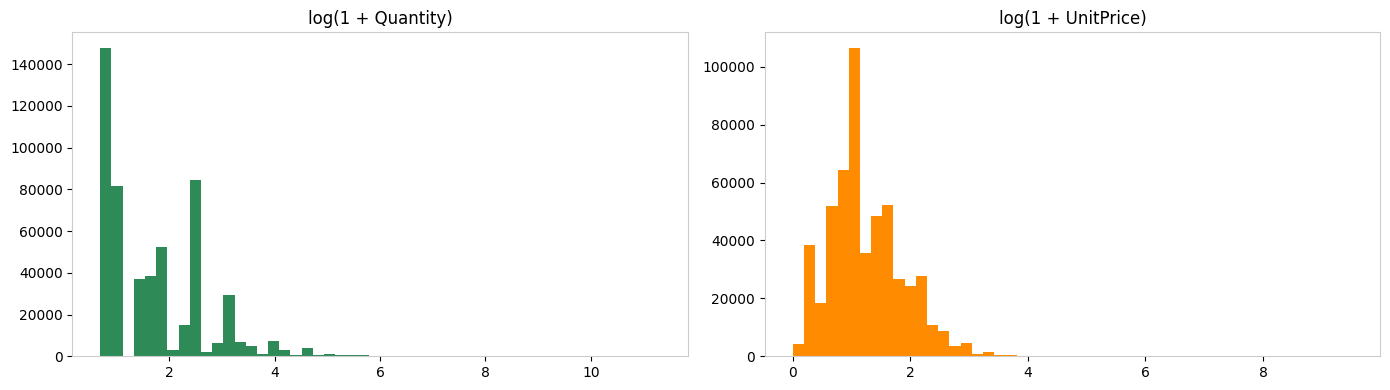

In [6]:
pos = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(np.log1p(pos['Quantity']), bins=50, color='seagreen')
ax[0].set_title('log(1 + Quantity)')
ax[1].hist(np.log1p(pos['UnitPrice']), bins=50, color='darkorange')
ax[1].set_title('log(1 + UnitPrice)')
plt.tight_layout(); plt.show()

### *2.3 Análisis Temporal*

Facturas por mes y por hora del día. Se aprecia el pico previo a Navidad y que dic-2011 está incompleto (solo hasta el día 9).

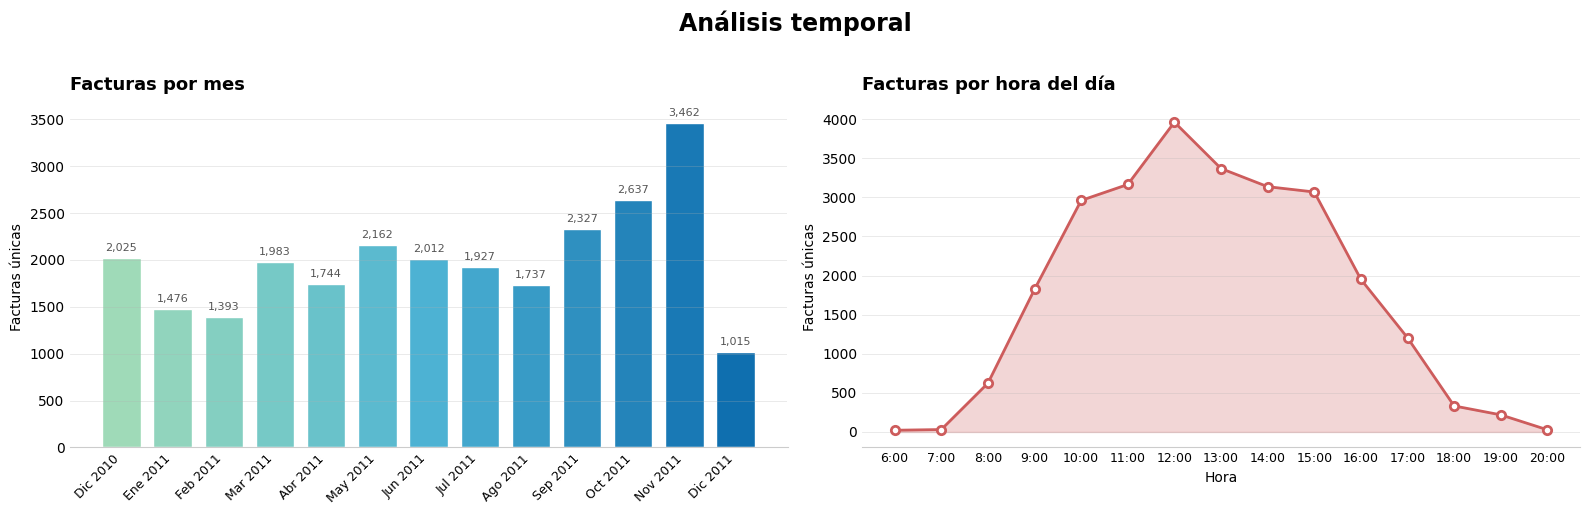

In [7]:
tmp = df.copy()
tmp['month'] = tmp['InvoiceDate'].dt.to_period('M')
tmp['hour']  = tmp['InvoiceDate'].dt.hour

# Facturas únicas por mes
monthly = tmp.groupby('month')['InvoiceNo'].nunique()

# Etiquetas con nombre de mes + año (Dic 2010, Ene 2011...)
meses_es = {1:'Ene', 2:'Feb', 3:'Mar', 4:'Abr', 5:'May', 6:'Jun',
            7:'Jul', 8:'Ago', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dic'}
labels = [f"{meses_es[p.month]} {p.year}" for p in monthly.index]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Análisis temporal', fontsize=17, fontweight='bold', y=1.02)

# ---------- Panel 1: Facturas por mes ----------
colors = plt.cm.GnBu(np.linspace(0.4, 0.85, len(monthly)))
bars = ax[0].bar(range(len(monthly)), monthly.values, color=colors, edgecolor='white', width=0.75)
ax[0].set_xticks(range(len(monthly)))
ax[0].set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax[0].set_title('Facturas por mes', fontsize=13, fontweight='semibold', pad=12, loc='left')
ax[0].set_ylabel('Facturas únicas')

for b, v in zip(bars, monthly.values):
    ax[0].text(b.get_x() + b.get_width()/2, v + monthly.max()*0.015,
               f'{v:,}', ha='center', va='bottom', fontsize=8, color='#555')

# ---------- Panel 2: Facturas por hora ----------
hourly = tmp.groupby('hour')['InvoiceNo'].nunique()
ax[1].fill_between(hourly.index, hourly.values, alpha=0.25, color='indianred')
ax[1].plot(hourly.index, hourly.values, marker='o', color='indianred',
           markersize=6, markerfacecolor='white', markeredgewidth=2, linewidth=2)
ax[1].set_title('Facturas por hora del día', fontsize=13, fontweight='semibold', pad=12, loc='left')
ax[1].set_xlabel('Hora'); ax[1].set_ylabel('Facturas únicas')
ax[1].set_xticks(hourly.index)
ax[1].set_xticklabels([f'{h}:00' for h in hourly.index], fontsize=9)

# ---------- Limpieza estética ----------
for a in ax:
    a.grid(axis='y', alpha=0.3, linewidth=0.6)
    for spine in ['top', 'right']:
        a.spines[spine].set_visible(False)
    a.spines['left'].set_visible(False)
    a.tick_params(length=0)

plt.tight_layout()
plt.show()

### *2.4 Tamaño de la cesta*

Las facturas cuyo `InvoiceNo` empieza por **C** son cancelaciones (Quantity negativa) y no representan una compra conjunta real, así que se excluyen. Medimos cuántos productos distintos tiene cada factura: las de un solo producto no generan ninguna arista.

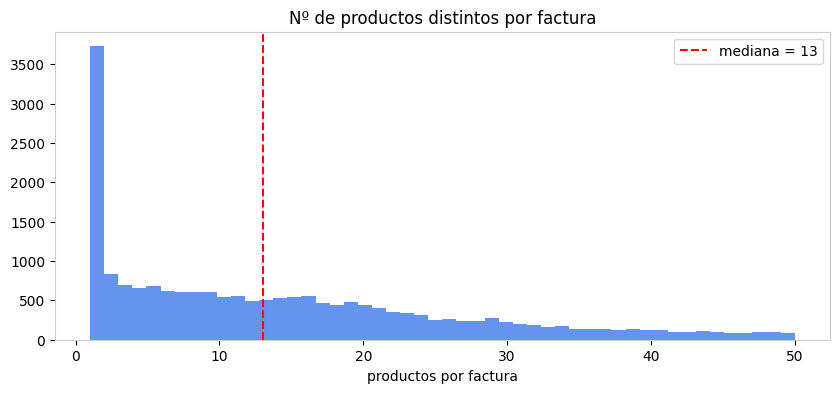

Cestas con 1 solo producto: 3,726 (16.9%)


In [8]:
cesta = df[~df['is_cancel']].groupby('InvoiceNo')['StockCode'].nunique()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cesta[cesta <= 50], bins=50, color='cornflowerblue')
ax.axvline(cesta.median(), color='red', ls='--', label=f'mediana = {cesta.median():.0f}')
ax.set_title('Nº de productos distintos por factura')
ax.set_xlabel('productos por factura'); ax.legend()
plt.show()

print(f'Cestas con 1 solo producto: {(cesta == 1).sum():,} ({(cesta==1).mean()*100:.1f}%)')

## *3. Limpieza de datos*

`CustomerID` tiene muchos nulos, pero no lo imputamos: el proyecto trabaja con productos y facturas, no con clientes.

Revisamos los **códigos incoherentes** en `StockCode` y `Description`:

In [9]:
df['StockCode']   = df['StockCode'].astype(str).str.strip().str.upper()
df['Description'] = df['Description'].str.strip().str.upper()

# Un producto real = 5 dígitos + letras opcionales (85123A, 71053, 15056BL...)
es_producto = df['StockCode'].str.match(r'^\d{5}[A-Z]*$')

# Códigos que se descartan (POST, DOT, M, AMAZONFEE...)
df.loc[~es_producto, 'StockCode'].value_counts().head(20)

StockCode
POST            1256
DOT              710
M                572
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
GIFT_0001_20      10
GIFT_0001_10       9
GIFT_0001_30       8
DCGS0003           5
GIFT_0001_50       4
PADS               4
GIFT_0001_40       3
B                  3
DCGS0076           2
Name: count, dtype: int64

Descartamos cancelaciones, cantidades y precios no positivos, códigos especiales (POST, DOT, M, AMAZONFEE…) y duplicados. Esto se debe a que **no representan compras** reales de productos reales.

In [10]:
df_clean = df[
    (~df['is_cancel']) &
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0) &
    es_producto &
    (df['Description'].notna())
].copy()

df_clean = df_clean.drop_duplicates(subset=['InvoiceNo', 'StockCode'])

print(f'Filas: {len(df):,} → {len(df_clean):,} ({len(df_clean)/len(df)*100:.1f}%)')
print(f'Productos únicos: {df_clean.StockCode.nunique():,}')
print(f'Facturas únicas: {df_clean.InvoiceNo.nunique():,}')

Filas: 541,909 → 517,254 (95.5%)
Productos únicos: 3,791
Facturas únicas: 19,773


In [11]:
d = df_clean.groupby('StockCode')['Description'].nunique()
print(f'Códigos con más de una descripción: {(d > 1).sum()}')
c = df_clean.groupby('Description')['StockCode'].nunique()
print(f'Descripciones asignadas a más de un código: {(c > 1).sum()}')

Códigos con más de una descripción: 212


Descripciones asignadas a más de un código: 26


## *4. Construcción del grafo de co-ocurrencia*

Cada producto es un nodo. Dos productos se conectan si aparecen en la misma factura. El peso de la arista es el número de facturas en las que coinciden.

In [12]:
# Agrupar productos por factura
basket = df_clean.groupby('InvoiceNo')['Description'].apply(lambda x: list(set(x)))

# Contar pares de co-ocurrencia
pair_counts = Counter()
for items in basket:
    if 2 <= len(items) <= 30:  # evitar cestas enormes que explotan la combinatoria
        for pair in combinations(sorted(items), 2):
            pair_counts[pair] += 1

print(f'Pares únicos de co-ocurrencia: {len(pair_counts):,}')

Pares únicos de co-ocurrencia: 731,383


Creamos un grafo simple, no dirigido y ponderado.

In [13]:
# Construir el grafo (no dirigido - relación simétrica)
G = nx.Graph()
for (p1, p2), weight in pair_counts.items():
    G.add_edge(p1, p2, weight=weight)

print(f'Nodos (productos): {G.number_of_nodes():,}')
print(f'Aristas (co-ocurrencias): {G.number_of_edges():,}')

Nodos (productos): 3,671
Aristas (co-ocurrencias): 731,383


## *5. Exploración del grafo*

Métricas básicas de la red y distribución del grado (nº de conexiones por producto). Un grado alto indica un producto que se combina con muchos otros.

In [14]:
degrees = dict(G.degree())

metrics = {
    'Nodos': G.number_of_nodes(),
    'Aristas': G.number_of_edges(),
    'Densidad': round(nx.density(G), 4),
    'Grado medio': round(np.mean(list(degrees.values())), 1),
    'Grado máximo': max(degrees.values()),
    'Componentes conexas': nx.number_connected_components(G),
}
pd.Series(metrics, name='valor')

Nodos                    3671.0000
Aristas                731383.0000
Densidad                    0.1086
Grado medio               398.5000
Grado máximo             2419.0000
Componentes conexas         2.0000
Name: valor, dtype: float64

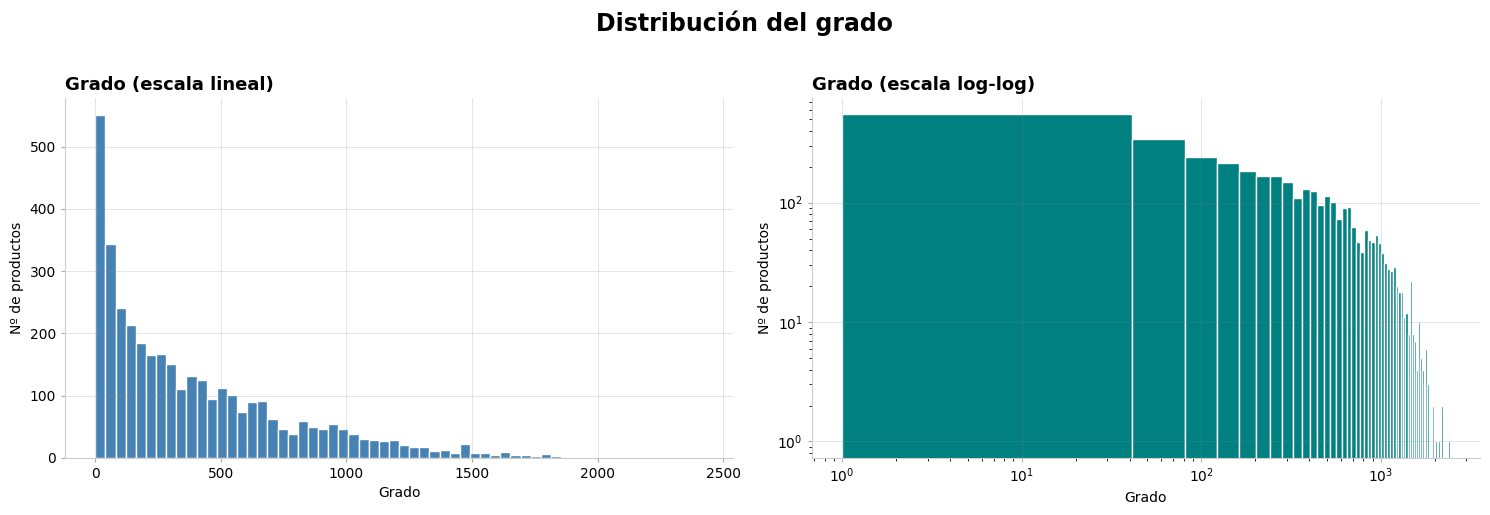

In [15]:
# Distribución del grado
deg_vals = list(degrees.values())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Distribución del grado', fontsize=17, fontweight='bold', y=1.02)

ax[0].hist(deg_vals, bins=60, color='steelblue', edgecolor='white')
ax[0].set_title('Grado (escala lineal)', fontsize=13, fontweight='semibold', loc='left')
ax[0].set_xlabel('Grado'); ax[0].set_ylabel('Nº de productos')

ax[1].hist(deg_vals, bins=60, color='teal', edgecolor='white')
ax[1].set_yscale('log'); ax[1].set_xscale('log')
ax[1].set_title('Grado (escala log-log)', fontsize=13, fontweight='semibold', loc='left')
ax[1].set_xlabel('Grado'); ax[1].set_ylabel('Nº de productos')

for a in ax:
    a.grid(axis='both', alpha=0.25, linewidth=0.6, color='#888')
    a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
    a.tick_params(length=3, color='#aaa')

plt.tight_layout(); plt.show()

## *6. Detección de comunidades (Louvain)*

Agrupamos los productos en comunidades: conjuntos de nodos densamente conectados entre sí. Cada comunidad representa productos que se compran juntos con frecuencia.

In [16]:
# Ejecutar Louvain
partition = community_louvain.best_partition(G, weight='weight', random_state=42)

n_communities = len(set(partition.values()))
print(f'Comunidades detectadas: {n_communities}')

# Tamaño de cada comunidad
comm_sizes = pd.Series(partition).value_counts().sort_index()
comm_sizes.name = 'productos'
print(f'\nTop 10 comunidades más grandes:')
comm_sizes.sort_values(ascending=False).head(10)

Comunidades detectadas: 8

Top 10 comunidades más grandes:


0    1296
1     735
2     701
4     394
3     374
6      99
7      70
5       2
Name: productos, dtype: int64

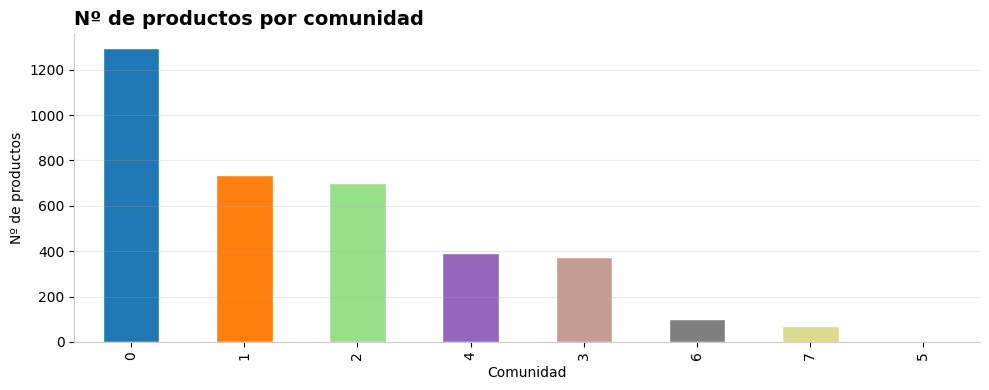

In [17]:
# Distribución del tamaño de comunidades
fig, ax = plt.subplots(figsize=(10, 4))
comm_sizes.sort_values(ascending=False).plot(
    kind='bar', color=plt.cm.tab20(np.linspace(0, 1, len(comm_sizes))),
    edgecolor='white', ax=ax
)
ax.set_title('Nº de productos por comunidad', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Comunidad'); ax.set_ylabel('Nº de productos')
ax.grid(axis='y', alpha=0.25); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

## *7. Visualización de una comunidad*

Mostramos la comunidad más grande como grafo coloreado. Los nodos más conectados aparecen más grandes.

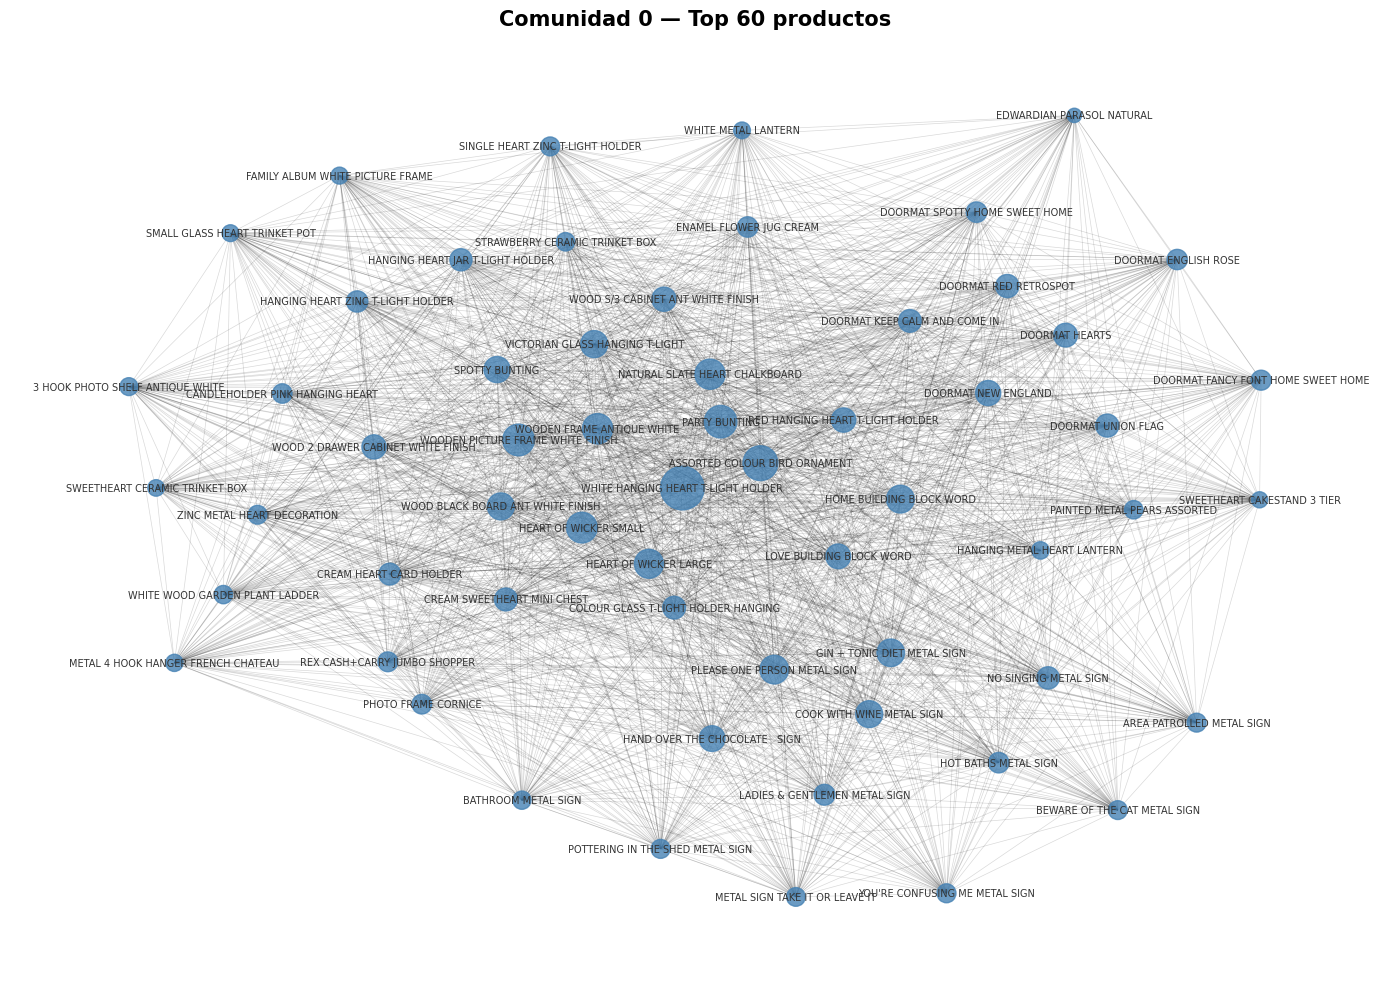

In [18]:
# Seleccionar la comunidad más grande
biggest_comm = comm_sizes.idxmax()
nodes_comm = [n for n, c in partition.items() if c == biggest_comm]

# Subgrafo de esa comunidad
sub = G.subgraph(nodes_comm)

# Si es muy grande, quedarnos con los nodos de mayor grado ponderado
MAX_NODES = 60
if len(sub) > MAX_NODES:
    top_nodes = sorted(sub.nodes(), key=lambda n: sub.degree(n, weight='weight'), reverse=True)[:MAX_NODES]
    sub = G.subgraph(top_nodes)

# Layout y tamaño proporcional al grado
pos = nx.spring_layout(sub, k=0.5, seed=42)
node_sizes = [sub.degree(n, weight='weight') * 0.3 for n in sub.nodes()]
edge_weights = [sub[u][v]['weight'] for u, v in sub.edges()]

fig, ax = plt.subplots(figsize=(14, 10))
nx.draw_networkx_edges(sub, pos, alpha=0.15, width=0.5, ax=ax)
nx.draw_networkx_nodes(sub, pos, node_size=node_sizes, node_color='steelblue', alpha=0.8, ax=ax)
nx.draw_networkx_labels(sub, pos, font_size=7, font_color='#333', ax=ax)
ax.set_title(f'Comunidad {biggest_comm} — Top {len(sub)} productos', fontsize=15, fontweight='bold')
ax.axis('off')
plt.tight_layout(); plt.show()

## *8. Motor de recomendación*

Dado un producto, recomendamos los productos de su misma comunidad. Comparamos dos criterios de ordenación:
- **Co-ocurrencias**: peso de la arista (cuántas veces se compraron juntos).
- **Grado interno**: los productos más conectados dentro de la comunidad.

In [19]:
def recomendar(producto, G, partition, top_n=5):
    """
    Dado un producto, devuelve los top_n productos más co-comprados
    dentro de su misma comunidad.
    """
    if producto not in partition:
        return f'"{producto}" no encontrado en el grafo.'
    
    comm = partition[producto]
    vecinos = G[producto]
    
    # Filtrar vecinos que estén en la misma comunidad
    recomendaciones = {
        vecino: data['weight']
        for vecino, data in vecinos.items()
        if partition.get(vecino) == comm
    }
    
    # Ordenar por peso descendente
    recomendaciones = sorted(recomendaciones.items(), key=lambda x: x[1], reverse=True)
    
    return pd.DataFrame(recomendaciones[:top_n], columns=['Producto recomendado', 'Co-ocurrencias'])

La alternativa ordena por centralidad dentro de la comunidad, sin exigir que el producto sea vecino directo:

In [20]:
def recomendar_por_grado(producto, G, partition, top_n=5):
    """
    Recomienda productos de la misma comunidad,
    ordenados por su grado dentro de esa comunidad (los más conectados primero).
    """
    if producto not in partition:
        return f'"{producto}" no encontrado en el grafo.'
    
    comm = partition[producto]
    
    # Todos los productos de la misma comunidad (excepto el propio)
    misma_comm = [n for n, c in partition.items() if c == comm and n != producto]
    
    # Subgrafo de la comunidad para calcular grado interno
    sub = G.subgraph(misma_comm + [producto])
    
    # Ordenar por grado dentro de la comunidad
    ranking = sorted(misma_comm, key=lambda n: sub.degree(n), reverse=True)
    
    return pd.DataFrame(ranking[:top_n], columns=['Producto recomendado'])

In [21]:
# Ejemplo: un producto concreto y sus recomendaciones con ambos criterios
ejemplo = list(partition.keys())[0]
print(f'Producto: "{ejemplo}"  ·  comunidad {partition[ejemplo]}')
display(recomendar(ejemplo, G, partition, top_n=10))
display(recomendar_por_grado(ejemplo, G, partition, top_n=10))

Producto: "CREAM CUPID HEARTS COAT HANGER"  ·  comunidad 0


,Producto recomendado,Co-ocurrencias
0,WHITE HANGING HEART T-LIGHT HOLDER,39
1,WOODEN FRAME ANTIQUE WHITE,29
2,WOODEN PICTURE FRAME WHITE FINISH,28
3,WOOD 2 DRAWER CABINET WHITE FINISH,26
4,WOOD S/3 CABINET ANT WHITE FINISH,24
5,METAL 4 HOOK HANGER FRENCH CHATEAU,20
6,WHITE METAL LANTERN,19
7,ENCHANTED BIRD COATHANGER 5 HOOK,19
8,GLASS STAR FROSTED T-LIGHT HOLDER,15
9,RETRO COFFEE MUGS ASSORTED,14


,Producto recomendado
0,WHITE HANGING HEART T-LIGHT HOLDER
1,PARTY BUNTING
2,ASSORTED COLOUR BIRD ORNAMENT
3,REX CASH+CARRY JUMBO SHOPPER
4,VICTORIAN GLASS HANGING T-LIGHT
5,NATURAL SLATE HEART CHALKBOARD
6,HEART OF WICKER SMALL
7,WOODEN FRAME ANTIQUE WHITE
8,HEART OF WICKER LARGE
9,WOODEN PICTURE FRAME WHITE FINISH


In [22]:
# Probar con varios productos de distintas comunidades
productos_test = [list(partition.keys())[i] for i in [0, 100, 500]]

for p in productos_test:
    print(f'\n{"="*60}')
    print(f' Producto: "{p}"')
    print(f' Comunidad: {partition[p]}')
    print(f'{"="*60}')
    display(recomendar(p, G, partition, top_n=5))


 Producto: "CREAM CUPID HEARTS COAT HANGER"
 Comunidad: 0


,Producto recomendado,Co-ocurrencias
0,WHITE HANGING HEART T-LIGHT HOLDER,39
1,WOODEN FRAME ANTIQUE WHITE,29
2,WOODEN PICTURE FRAME WHITE FINISH,28
3,WOOD 2 DRAWER CABINET WHITE FINISH,26
4,WOOD S/3 CABINET ANT WHITE FINISH,24



 Producto: "ORGANISER WOOD ANTIQUE WHITE"
 Comunidad: 0


,Producto recomendado,Co-ocurrencias
0,WHITE HANGING HEART T-LIGHT HOLDER,10
1,WHITE WOOD GARDEN PLANT LADDER,9
2,NATURAL SLATE HEART CHALKBOARD,6
3,SET 3 PAPER VINTAGE CHICK PAPER EGG,5
4,KEY CABINET MA CAMPAGNE,4



 Producto: "WOODEN TREE CHRISTMAS SCANDINAVIAN"
 Comunidad: 1


,Producto recomendado,Co-ocurrencias
0,WOODEN STAR CHRISTMAS SCANDINAVIAN,93
1,WOODEN HEART CHRISTMAS SCANDINAVIAN,78
2,PAPER CHAIN KIT 50'S CHRISTMAS,18
3,GINGHAM HEART DECORATION,17
4,SET OF 3 WOODEN TREE DECORATIONS,14


## *9. Evaluación cualitativa*

Visualizamos la red ego (vecindario directo) de un producto para comprobar que las recomendaciones tienen sentido temático. Para que sea legible, mostramos solo sus vecinos más fuertes.

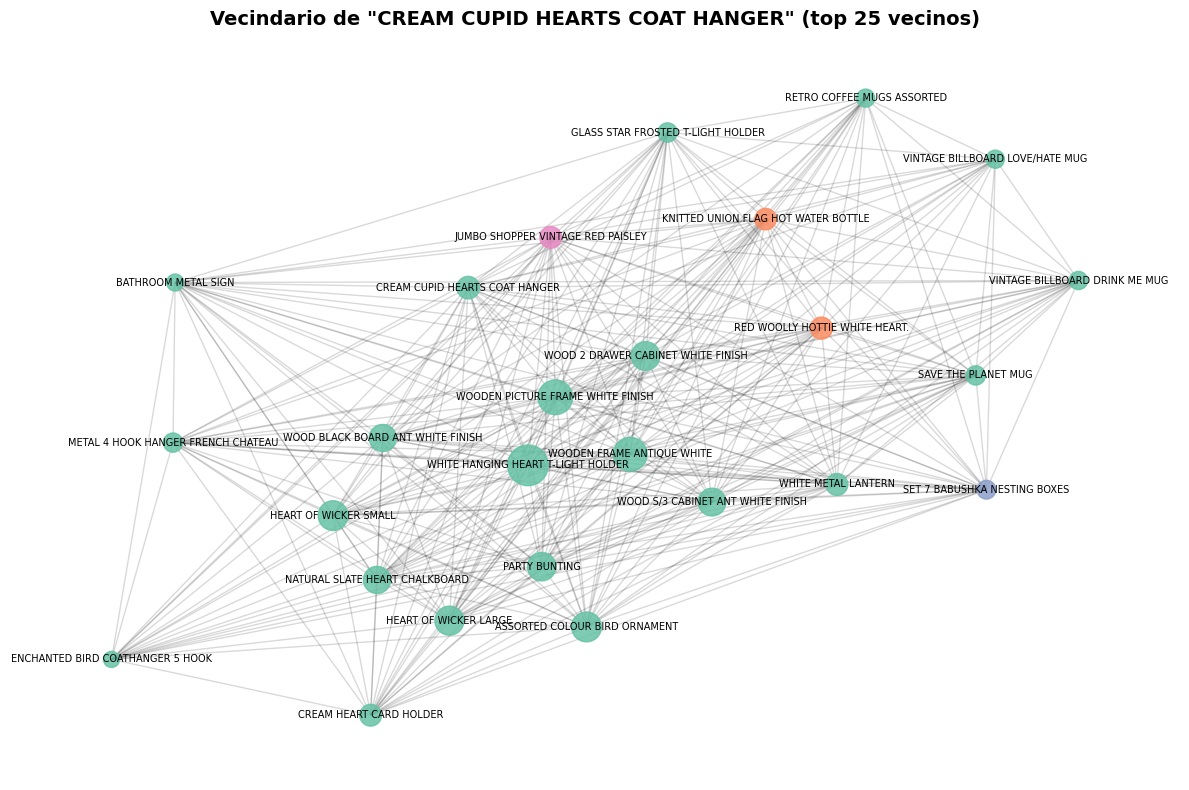

In [23]:
def plot_ego(producto, G, partition, max_vecinos=25):
    """Dibuja el vecindario de un producto (sus vecinos más fuertes), coloreado por comunidad."""
    vecinos = sorted(G[producto], key=lambda v: G[producto][v]['weight'], reverse=True)[:max_vecinos]
    ego = G.subgraph([producto] + vecinos)

    comms = sorted(set(partition[n] for n in ego.nodes()))
    cmap = {c: plt.cm.Set2(i % 8) for i, c in enumerate(comms)}
    colors = [cmap[partition[n]] for n in ego.nodes()]
    sizes = [ego.degree(n, weight='weight') * 0.5 + 50 for n in ego.nodes()]

    pos = nx.spring_layout(ego, k=0.6, seed=42)
    fig, ax = plt.subplots(figsize=(12, 8))
    nx.draw_networkx_edges(ego, pos, alpha=0.15, ax=ax)
    nx.draw_networkx_nodes(ego, pos, node_color=colors, node_size=sizes, alpha=0.85, ax=ax)
    nx.draw_networkx_labels(ego, pos, font_size=7, ax=ax)
    ax.set_title(f'Vecindario de "{producto}" (top {len(vecinos)} vecinos)', fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.tight_layout(); plt.show()

plot_ego(ejemplo, G, partition)

## Conclusiones y siguiente paso
- La co-compra forma comunidades temáticas reconocibles y las recomendaciones dentro de cada comunidad tienen sentido a simple vista.
- Esta versión **no mide el rendimiento**: no separa train/test y el peso bruto favorece a los superventas.
- `02_networkx_leiden_neo4j.ipynb` resuelve ambas cosas (holdout por factura, Jaccard/Lift, refinado con Leiden y comparación con un baseline) y replica el grafo en **Neo4j** con GDS y Cypher.